### **Step 1 — Import libraries**

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("Libraries imported successfully!")

Libraries imported successfully!


### **Step 2: Upload and load your dataset**

In [37]:
from google.colab import files

uploaded = files.upload()

Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data (2).csv


In [38]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


### **Step 3: Inspect the original dataset**

In [39]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all"))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB

Missing values:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease      

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
count,5110.000000,5110,5110.000000,5110.000000,5110.000000,5110,5110,5110,5110.000000,4909.000000,5110,5110.000000
unique,NaN,3,NaN,NaN,NaN,2,5,2,NaN,NaN,4,NaN
top,NaN,Female,NaN,NaN,NaN,Yes,Private,Urban,NaN,NaN,never smoked,NaN
freq,NaN,2994,NaN,NaN,NaN,3353,2925,2596,NaN,NaN,1892,NaN
mean,36517.829354,NaN,43.226614,0.097456,0.054012,NaN,NaN,NaN,106.147677,28.893237,NaN,0.048728
std,21161.721625,NaN,22.612647,0.296607,0.226063,NaN,NaN,NaN,45.283560,7.854067,NaN,0.215320
min,67.000000,NaN,0.080000,0.000000,0.000000,NaN,NaN,NaN,55.120000,10.300000,NaN,0.000000
25%,17741.250000,NaN,25.000000,0.000000,0.000000,NaN,NaN,NaN,77.245000,23.500000,NaN,0.000000
50%,36932.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN,NaN,91.885000,28.100000,NaN,0.000000
75%,54682.000000,NaN,61.000000,0.000000,0.000000,NaN,NaN,NaN,114.090000,33.100000,NaN,0.000000


### **Step 4: Split the data into 70% training and 30% testing**

In [40]:
TARGET = "stroke"

X = df.drop(columns=["stroke", "id"])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (3577, 10)
Testing features: (1533, 10)

Training target distribution:
stroke
0    3403
1     174
Name: count, dtype: int64

Testing target distribution:
stroke
0    1458
1      75
Name: count, dtype: int64


### **Step 5: Perform EDA on the training data only**

Training data sample:


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
2226,Female,52.0,0,0,Yes,Govt_job,Rural,107.84,22.0,formerly smoked
3927,Female,62.0,0,0,Yes,Private,Urban,88.32,36.3,Unknown
3358,Male,81.0,0,1,No,Self-employed,Rural,95.49,29.4,Unknown
4152,Male,55.0,0,0,Yes,Self-employed,Rural,73.57,28.0,smokes
4866,Female,37.0,0,0,Yes,Private,Urban,103.66,36.1,smokes



Training data statistics:


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
count,3577,3577.000000,3577.000000,3577.000000,3577,3577,3577,3577.000000,3429.000000,3577
unique,3,NaN,NaN,NaN,2,5,2,NaN,NaN,4
top,Female,NaN,NaN,NaN,Yes,Private,Urban,NaN,NaN,never smoked
freq,2093,NaN,NaN,NaN,2361,2044,1803,NaN,NaN,1327
mean,NaN,43.250433,0.096170,0.053956,NaN,NaN,NaN,105.957414,28.867279,NaN
std,NaN,22.493077,0.294865,0.225962,NaN,NaN,NaN,44.945203,7.909601,NaN
min,NaN,0.080000,0.000000,0.000000,NaN,NaN,NaN,55.120000,10.300000,NaN
25%,NaN,26.000000,0.000000,0.000000,NaN,NaN,NaN,77.460000,23.500000,NaN
50%,NaN,45.000000,0.000000,0.000000,NaN,NaN,NaN,91.710000,28.000000,NaN
75%,NaN,61.000000,0.000000,0.000000,NaN,NaN,NaN,113.630000,33.100000,NaN



Missing values in training data:
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  148
smoking_status         0
dtype: int64


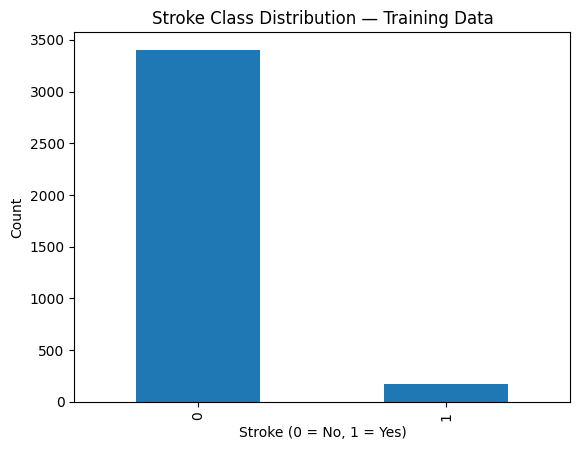

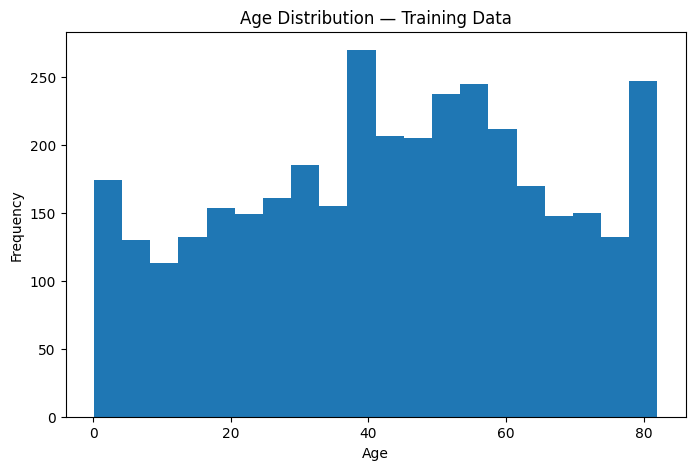

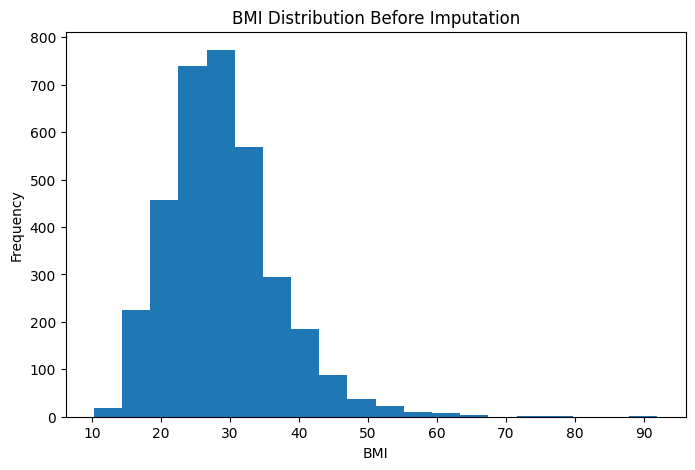

In [41]:
print("Training data sample:")
display(X_train.head())

print("\nTraining data statistics:")
display(X_train.describe(include="all"))

print("\nMissing values in training data:")
print(X_train.isnull().sum())

# Target distribution
y_train.value_counts().sort_index().plot(
    kind="bar",
    title="Stroke Class Distribution — Training Data"
)
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

# Age distribution
plt.figure(figsize=(8, 5))
plt.hist(X_train["age"], bins=20)
plt.title("Age Distribution — Training Data")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

# BMI distribution, including missing values
plt.figure(figsize=(8, 5))
plt.hist(X_train["bmi"].dropna(), bins=20)
plt.title("BMI Distribution Before Imputation")
plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.show()

### **Step 6: Add feature engineering**

In [42]:
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

age_bins = [-np.inf, 17, 39, 59, np.inf]
age_labels = ["Under 18", "18-39", "40-59", "60 and above"]

X_train_fe["age_group"] = pd.cut(
    X_train_fe["age"],
    bins=age_bins,
    labels=age_labels
)

X_test_fe["age_group"] = pd.cut(
    X_test_fe["age"],
    bins=age_bins,
    labels=age_labels
)

print("Sample after feature engineering:")
display(X_train_fe.head())

Sample after feature engineering:


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,age_group
2226,Female,52.0,0,0,Yes,Govt_job,Rural,107.84,22.0,formerly smoked,40-59
3927,Female,62.0,0,0,Yes,Private,Urban,88.32,36.3,Unknown,60 and above
3358,Male,81.0,0,1,No,Self-employed,Rural,95.49,29.4,Unknown,60 and above
4152,Male,55.0,0,0,Yes,Self-employed,Rural,73.57,28.0,smokes,40-59
4866,Female,37.0,0,0,Yes,Private,Urban,103.66,36.1,smokes,18-39


## **Step 7: Handle missing values, encode categories, and scale numerical features**

In [43]:
numeric_features = X_train_fe.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train_fe.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_array = preprocessor.fit_transform(X_train_fe)
X_test_array = preprocessor.transform(X_test_fe)

feature_names = preprocessor.get_feature_names_out()

X_train_clean = pd.DataFrame(
    X_train_array.toarray() if hasattr(X_train_array, "toarray") else X_train_array,
    columns=feature_names,
    index=X_train_fe.index
)

X_test_clean = pd.DataFrame(
    X_test_array.toarray() if hasattr(X_test_array, "toarray") else X_test_array,
    columns=feature_names,
    index=X_test_fe.index
)

print("Training data after preprocessing:")
display(X_train_clean.head())

print("Testing data after preprocessing:")
display(X_test_clean.head())

print("Remaining missing values in training features:",
      X_train_clean.isnull().sum().sum())

Training data after preprocessing:


,numeric__age,numeric__hypertension,numeric__heart_disease,numeric__avg_glucose_level,numeric__bmi,categorical__gender_Female,categorical__gender_Male,categorical__gender_Other,categorical__ever_married_No,categorical__ever_married_Yes,...,categorical__Residence_type_Rural,categorical__Residence_type_Urban,categorical__smoking_status_Unknown,categorical__smoking_status_formerly smoked,categorical__smoking_status_never smoked,categorical__smoking_status_smokes,categorical__age_group_18-39,categorical__age_group_40-59,categorical__age_group_60 and above,categorical__age_group_Under 18
2226,0.389044,-0.326194,-0.238816,0.041892,-0.882035,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3927,0.833687,-0.326194,-0.238816,-0.392475,0.964308,1.0,0.0,0.0,0.0,1.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3358,1.678510,-0.326194,4.187324,-0.232925,0.073415,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4152,0.522437,-0.326194,-0.238816,-0.720699,-0.107346,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4866,-0.277921,-0.326194,-0.238816,-0.051123,0.938485,1.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


Testing data after preprocessing:


,numeric__age,numeric__hypertension,numeric__heart_disease,numeric__avg_glucose_level,numeric__bmi,categorical__gender_Female,categorical__gender_Male,categorical__gender_Other,categorical__ever_married_No,categorical__ever_married_Yes,...,categorical__Residence_type_Rural,categorical__Residence_type_Urban,categorical__smoking_status_Unknown,categorical__smoking_status_formerly smoked,categorical__smoking_status_never smoked,categorical__smoking_status_smokes,categorical__age_group_18-39,categorical__age_group_40-59,categorical__age_group_60 and above,categorical__age_group_Under 18
4223,0.389044,-0.326194,-0.238816,-1.031120,2.836475,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2230,-1.567387,-0.326194,-0.238816,-0.364660,-1.295203,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4612,-0.589172,-0.326194,-0.238816,-0.019525,-0.430133,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4100,-1.167208,-0.326194,-0.238816,0.076383,-0.326841,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2983,-0.544707,-0.326194,-0.238816,-0.816606,-0.907858,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


Remaining missing values in training features: 0


### **Step 8: Apply normalization or distribution adjustment**

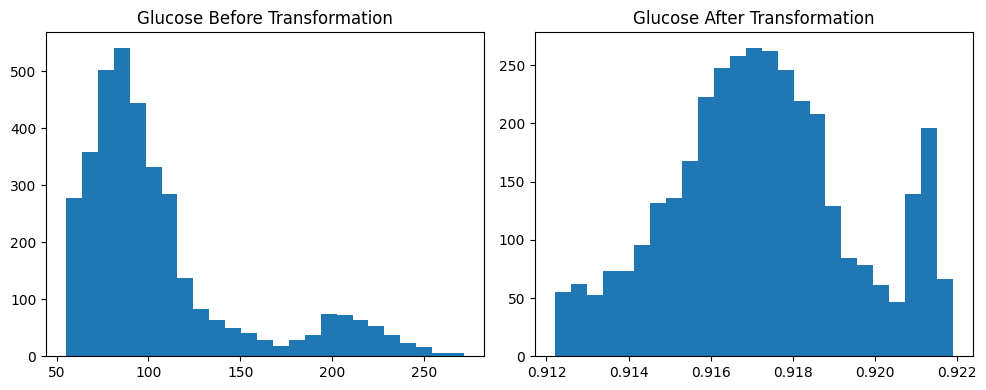

In [44]:
glucose_train = X_train_fe[["avg_glucose_level"]].copy()
glucose_test = X_test_fe[["avg_glucose_level"]].copy()

glucose_median = glucose_train["avg_glucose_level"].median()

glucose_train["avg_glucose_level"] = glucose_train[
    "avg_glucose_level"
].fillna(glucose_median)

glucose_test["avg_glucose_level"] = glucose_test[
    "avg_glucose_level"
].fillna(glucose_median)

transformer = PowerTransformer(
    method="yeo-johnson",
    standardize=False
)

glucose_train_transformed = transformer.fit_transform(glucose_train)
glucose_test_transformed = transformer.transform(glucose_test)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(glucose_train["avg_glucose_level"], bins=25)
plt.title("Glucose Before Transformation")

plt.subplot(1, 2, 2)
plt.hist(glucose_train_transformed, bins=25)
plt.title("Glucose After Transformation")

plt.tight_layout()
plt.show()

### **Step 9: Balance the training classes**

In [45]:
%pip install imbalanced-learn -q

Class counts before balancing:
stroke
0    3403
1     174
Name: count, dtype: int64

Class counts after balancing:
stroke
0    3403
1    3403
Name: count, dtype: int64


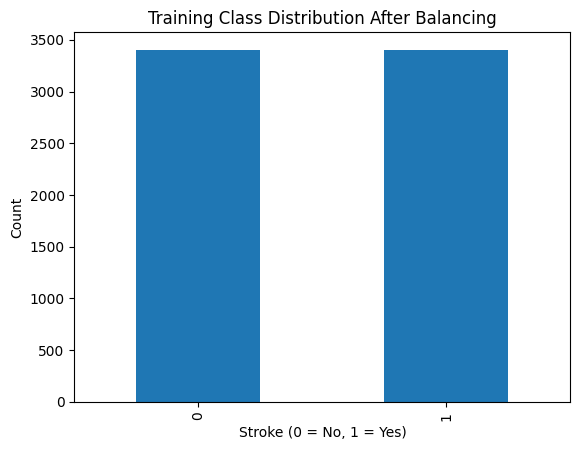

In [46]:
from imblearn.over_sampling import RandomOverSampler

print("Class counts before balancing:")
print(y_train.value_counts())

sampler = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = sampler.fit_resample(
    X_train_clean,
    y_train
)

print("\nClass counts after balancing:")
print(y_train_balanced.value_counts())

y_train_balanced.value_counts().sort_index().plot(
    kind="bar",
    title="Training Class Distribution After Balancing"
)
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

### **Step 10: Compare the data before and after cleaning**

In [47]:
print("Original training sample:")
display(X_train.head())

print("\nCleaned training sample:")
display(X_train_clean.head())

print("\nOriginal training shape:", X_train.shape)
print("Cleaned training shape:", X_train_clean.shape)
print("Balanced training shape:", X_train_balanced.shape)

Original training sample:


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
2226,Female,52.0,0,0,Yes,Govt_job,Rural,107.84,22.0,formerly smoked
3927,Female,62.0,0,0,Yes,Private,Urban,88.32,36.3,Unknown
3358,Male,81.0,0,1,No,Self-employed,Rural,95.49,29.4,Unknown
4152,Male,55.0,0,0,Yes,Self-employed,Rural,73.57,28.0,smokes
4866,Female,37.0,0,0,Yes,Private,Urban,103.66,36.1,smokes



Cleaned training sample:


,numeric__age,numeric__hypertension,numeric__heart_disease,numeric__avg_glucose_level,numeric__bmi,categorical__gender_Female,categorical__gender_Male,categorical__gender_Other,categorical__ever_married_No,categorical__ever_married_Yes,...,categorical__Residence_type_Rural,categorical__Residence_type_Urban,categorical__smoking_status_Unknown,categorical__smoking_status_formerly smoked,categorical__smoking_status_never smoked,categorical__smoking_status_smokes,categorical__age_group_18-39,categorical__age_group_40-59,categorical__age_group_60 and above,categorical__age_group_Under 18
2226,0.389044,-0.326194,-0.238816,0.041892,-0.882035,1.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3927,0.833687,-0.326194,-0.238816,-0.392475,0.964308,1.0,0.0,0.0,0.0,1.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3358,1.678510,-0.326194,4.187324,-0.232925,0.073415,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4152,0.522437,-0.326194,-0.238816,-0.720699,-0.107346,0.0,1.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4866,-0.277921,-0.326194,-0.238816,-0.051123,0.938485,1.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0



Original training shape: (3577, 10)
Cleaned training shape: (3577, 25)
Balanced training shape: (6806, 25)


In [48]:
cleaned_train = X_train_clean.copy()
cleaned_train["stroke"] = y_train.loc[X_train_clean.index]

cleaned_test = X_test_clean.copy()
cleaned_test["stroke"] = y_test.loc[X_test_clean.index]

cleaned_train.to_csv("cleaned_train.csv", index=False)
cleaned_test.to_csv("cleaned_test.csv", index=False)

print("Cleaned datasets saved successfully!")

Cleaned datasets saved successfully!
